# Exercice 2 — Analyser des données climatiques

Dans cet exercice, on utilise des données climatologiques mensuelles publiées par **Météo-France**
sur data.gouv.fr. Le fichier contient des observations de stations météorologiques du département
de l'Isère (38), de 1950 à 2024.

Source : [Données climatologiques de base — mensuelles](https://www.data.gouv.fr/datasets/donnees-climatologiques-de-base-mensuelles)

In [ ]:
# Run this cell to configure the notebook
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np

## Charger et découvrir les données

Le fichier est téléchargé directement depuis data.gouv.fr via le code suivant.

In [ ]:
# Exécutez ce code pour charger les données

weather_url = "https://www.data.gouv.fr/api/1/datasets/r/09d25a36-2e11-4f0b-b52b-4898ba53760c"

weather = pd.read_csv(
    weather_url,
    sep=";",
    usecols=["NUM_POSTE", "NOM_USUEL", "ALTI", "AAAAMM", "TX", "TN", "NBJORAG", "NBJSOLNG"],
    compression='gzip',
)

weather.head()

# backup solution if not working : 
# weather = pd.read_csv("https://raw.githubusercontent.com/thomaslvz/intro-python-student/refs/heads/main/data/MENSQ_38_previous-1950-2024.csv", sep=";", usecols=["NUM_POSTE", "NOM_USUEL", "ALTI", "AAAAMM", "TX", "TN", "NBJORAG", "NBJSOLNG"])

👉Allez parcourir la [documentation](https://www.data.gouv.fr/api/1/datasets/r/766dbe58-0c5a-428b-b76e-a24b3cd250e1) du jeu de données pour comprendre la signification des colonnes et valeur. Compléter alors la signification ci dessous : 

Contenu des colonnes : 

- `NUM_POSTE` : ____
- `NOM_USUEL` : ____
- `ALTI` :____
- `AAAAMM` : ____
- `TX` : ____
- `TN` : ____
- `NBJSOLNG` : ____
- `NBJORAG` : ____

👉 Afficher les dimensions du DataFrame, les noms des colonnes et les types de données.

In [ ]:
# YOUR CODE HERE


👉 Avec `info()` ou `isna().sum()`, repérer les colonnes qui contiennent des valeurs manquantes.

In [ ]:
# YOUR CODE HERE

## Nettoyage et préparation des données



### Calcul des températures moyennes

Dans le jeu de données, il n'y a que les températures min et max de chaque mois. On va calculer une température moyenne mensuelle, définie comme la moyenne de ces deux valeurs.

👉 Créez une colonne `'T'` contenant la température moyenne mensuelle.

In [ ]:
# YOUR CODE HERE

In [ ]:
# Exécutez la cellule pour vérifier votre travail
from verif import check_T
check_T(weather)

### Gestion des valeurs manquantes

👉 Supprimer les lignes pour lesquelles la température moyenne est manquante.
Stocker le résultat dans `weather_clean`.

In [ ]:
# YOUR CODE HERE

👉 Dans `weather_clean`, remplacez les valeurs manquantes de `'NBJSOLNG'` et `'NBJORAG'` par la valeur `0`.

In [ ]:
# YOUR CODE HERE

In [ ]:
# Exécutez la cellule pour vérifier votre travail
from verif import check_weather_missing
check_weather_missing(weather_clean)

### Gestion des types

Maintenant qu'on a enlevé les lignes qui ne nous intéresse pas, on peut remplacer `weather` par `weather_clean` pour travailler sur un DataFrame "propre".

👉 Exécutez la cellule ci-dessous.

In [ ]:
# Ne pas modifier cette cellule
weather = weather_clean.copy()

On travaille désormais sur `weather`.

👉 Dans `weather`, changez le type des colonnes `'NBJORAG'` et `'NBJSOLNG'` pour qu'elles soient de type `int`. 

In [ ]:
# YOUR CODE HERE

### Gestion des dates

La colonne `AAAAMM` contient une année et un mois sous la forme `YYYYMM`. Pandas reconnaît les dates au format `YYYYMMDD`, il va donc falloir modifier un peut cette colonne avant de pouvoir la convertir en date.

👉 Créez une nouvelle colonne `date`, qui contient la colonne `AAAAMM` convertie en chaîne de caractères.

In [ ]:
# YOUR CODE HERE

👉 Ajouter `'01'` à la fin de chaque valeur de la colonne `date` pour obtenir le format `YYYYMMDD` : `'01'` représentera le premier jour du mois.

*Indice : on pourra utiliser la concaténation `+` entre deux chaînes de caractères.*

In [ ]:
# YOUR CODE HERE

In [ ]:
# Exécutez la cellule pour vérifier votre travail
from verif import check_weather_date_col
check_weather_date_col(weather)

👉 Faites en sorte que le type de la colonne `date` soit bien un type `datetime`.

In [ ]:
# YOUR CODE HERE

### Filtrer les colonnes

👉 Dans `weather`, ne gardez que les colonnes qui nous intéressent, et dans cet ordre : 

- `date`
- `NOM_USUEL`
- `T`
- `NBJSOLNG`
- `NBJORAG` 
- `ALTI`

In [ ]:
# YOUR CODE HERE

### Créer une colonne pour les années

👉 Créez une colonne `year` contenant l'année de la mesure.

*Indice : on utilisera `.dt.year` sur la colonne `'date'`*

In [ ]:
# YOUR CODE HERE

In [ ]:
# Exécutez la cellule pour vérifier votre travail
from verif import check_weather_prepared
check_weather_prepared(weather)

## Focus sur la stations de Monestier-de-Clermont (Trièves)

📍 C'est où  Monestier-de-Clermont ? [Ici](https://cartes.app/?allez=Monestier-de-Clermont|r279272|5.63590|44.91835#17.5/44.922765/5.634335).

👉 Créez un dataframe `weather_monestier` ne contenant que les lignes de la station `'MONESTIER'`.

👉 Faites en sorte que les lignes soient indexées par la date.

In [ ]:
# YOUR CODE HERE

👉 Représenter (avec `.plot()`) le graphique de la colonne `T`. Pourquoi ce graphe n'est pas très lisible ?

In [ ]:
# YOUR CODE HERE

👉 A partir de `weather_monestier`, calculez la température moyenne par an en utilisant `.groupby('year')`, et stockez le résultat dans `monestier_annual`. Représentez ensuite graphiquement l'évolution de ces températures annuelles moyennes.

In [ ]:
# YOUR CODE HERE

👉 Triez les données de `monestier_annual` par ordre décroissant de température moyenne. Affichez ensuite les températures des 10 années les plus chaudes.


<details> 
<summary>💡 Vérifiez votre réponse</summary>

Par ordre décroissant, les 10 années les plus chaudes ddoivent être

- 2022 avec 11.55 °C environ
- 2023 avec 11.20 °C environ
- 2024 avec 11.00 °C environ
- 2020 avec 10.92 °C environ
- 2003 avec 10.82 °C environ
- 2018 avec 10.75 °C environ
- 1994 avec 10.69 °C environ
- 2014 avec 10.40 °C environ
- 1997 avec 10.40 °C environ
- 2015 avec 10.37 °C environ


</details>

In [ ]:
# YOUR CODE HERE

👉 Créez un DataFrame `df` qui contient, pour chaque année, le nombre total de jours d'orage et le nombre total de jours avec de la neige. Visualisez les données avec un `.plot()`. Que penser de ces informations ?

<details>
<summary>💡 Indice</summary

Pour créer `df`, on utilisera un `.groupby` et un `.agg` sur `weather_monestier`. Le dataframe obtenu doit ressembler à ceci : 

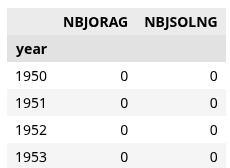

</details>

In [ ]:
# YOUR CODE HERE

## (optionnel) Regrouper les observations par année

On reprend le dataframe `weather` nettoyé précédemment, et contenant **toutes** les stations. On souhaite calculer la température moyenne observée chaque année, toutes stations confondues.

👉 Utiliser `groupby()` pour calculer la température moyenne annuelle.
Stocker le résultat dans `annual_temperature`.

In [ ]:
# YOUR CODE HERE

👉 Représenter graphiquement l'évolution de la température moyenne annuelle. 


In [ ]:
# YOUR CODE HERE

🤔 On remarque une tendance à la baisse des températures moyennes entre 1960 et 2010, ce qui va a l'encontre du constat de réchauffement climatique... Essayons-donc de voir s'il n'y a pas un biais dans cette observation.

👉 Utiliser `agg()` pour calculer pour chaque année :

- la moyenne de l'altitude des mesures observées
- le nombre de stations observées

Stocker le DataFrame obtenu dans `measure_stats`, puis visualisez son contenu avec `.plot()`.

In [ ]:
# YOUR CODE HERE

👉 Que se passe-t-il au fil du temps ? Le jeu de données fournit-il un ensemble de mesures comparables entre elles d'une année à l'autre ?

💡 On retiendra que l'analyse de données demande de la prudence : il y a parfois des biases dans les données qui peuvent fausser les conclusions.

🏆 Cet exercice est terminé !